# get count data for files of interest  

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

from urllib.parse import quote

PROJECT = "en.wikipedia.org"
BASE_URL = "https://xtools.wmcloud.org/api/page/articleinfo"

HEADERS = {
    "User-Agent": "HistoricalArchaeologyResearch/1.0 (Wikipedia revision analysis)"
}

In [2]:
ARTICLES = [
    "Vietnam War",
    "Watergate scandal",
    "Chernobyl disaster",
    "World War II",
    "September 11 attacks",
    "American Revolution",
    "French Revolution",
    "American Civil War",
    "World War I",
    "Cold War",
    "Fall of the Berlin Wall",
    "Russian Revolution",
    "Industrial Revolution",
    "Great Depression",
    "Holocaust",
    "Pearl Harbor attack",
    "D-Day",
    "Atomic bombings of Hiroshima and Nagasaki",
    "Korean War",
    "Cuban Missile Crisis",
    "Apollo 11 Moon landing",
    "Civil Rights Movement",
    "Assassination of John F. Kennedy",
    "Boston Tea Party",
    "Declaration of Independence",
    "Battle of Gettysburg",
    "Emancipation Proclamation",
    "Spanish-American War",
    "Great Fire of London",
    "Black Death",
    "Protestant Reformation",
    "Renaissance",
    "Magna Carta",
    "Fall of Constantinople",
    "Sinking of the Titanic",
    "Russian Civil War",
    "Chinese Revolution",
    "Cultural Revolution",
    "Vietnamese Declaration of Independence",
    "Indian Independence Movement",
    "Partition of India",
    "Rwandan Genocide",
    "Apartheid in South Africa",
    "Iranian Revolution",
    "Gulf War",
    "Iraq War",
    "Arab Spring",
    "Fukushima nuclear disaster",
    "Haitian Revolution",
    "Mexican Revolution",
]

print(f"Loaded {len(ARTICLES)} historical events.")

Loaded 50 historical events.


In [3]:
def get_revision_count(article):
    encoded_article = quote(article.replace(" ", "_"), safe="")

    url = f"{BASE_URL}/{PROJECT}/{encoded_article}"

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    response.raise_for_status()
    data = response.json()

    # Identify the revision count returned by XTools.
    possible_keys = [
        "revisions",
        "revision_count",
        "revisions_count"
    ]

    for key in possible_keys:
        if key in data and isinstance(data[key], (int, float)):
            return int(data[key])

    raise ValueError(
        f"Could not identify revision count for {article}. "
        f"API returned keys: {list(data.keys())}"
    )


results = []

for i, article in enumerate(ARTICLES, start=1):
    try:
        count = get_revision_count(article)

        results.append({
            "article": article,
            "revisions": count,
            "status": "Success"
        })

        print(f"[{i}/{len(ARTICLES)}] {article}: {count:,} revisions")

    except Exception as e:
        results.append({
            "article": article,
            "revisions": None,
            "status": str(e)
        })

        print(f"[{i}/{len(ARTICLES)}] ERROR - {article}: {e}")

    # Avoid sending requests too rapidly.
    time.sleep(1)

[1/50] Vietnam War: 19,378 revisions
[2/50] Watergate scandal: 9,955 revisions
[3/50] ERROR - Chernobyl disaster: Could not identify revision count for Chernobyl disaster. API returned keys: ['project', 'page', 'watchers', 'pageviews', 'pageviews_offset', 'error', 'elapsed_time']
[4/50] World War II: 28,609 revisions
[5/50] September 11 attacks: 22,585 revisions
[6/50] American Revolution: 8,957 revisions
[7/50] ERROR - French Revolution: Could not identify revision count for French Revolution. API returned keys: ['project', 'page', 'watchers', 'pageviews', 'pageviews_offset', 'error', 'elapsed_time']
[8/50] American Civil War: 14,930 revisions
[9/50] World War I: 20,277 revisions
[10/50] Cold War: 12,602 revisions
[11/50] Fall of the Berlin Wall: 542 revisions
[12/50] Russian Revolution: 5,322 revisions
[13/50] ERROR - Industrial Revolution: Could not identify revision count for Industrial Revolution. API returned keys: ['project', 'page', 'watchers', 'pageviews', 'pageviews_offset', 

In [4]:
df = pd.DataFrame(results)

successful = df.dropna(subset=["revisions"]).copy()

total_revisions = successful["revisions"].sum()
average_revisions = successful["revisions"].mean()
median_revisions = successful["revisions"].median()

print("=" * 50)
print("REVISION HISTORY STATISTICS")
print("=" * 50)

print(f"Articles requested:       {len(ARTICLES)}")
print(f"Articles successful:      {len(successful)}")
print(f"Articles failed:          {len(df) - len(successful)}")
print(f"Total revisions:          {total_revisions:,.0f}")
print(f"Average revisions/article: {average_revisions:,.2f}")
print(f"Median revisions/article:  {median_revisions:,.0f}")
print(f"Minimum revisions:         {successful['revisions'].min():,.0f}")
print(f"Maximum revisions:         {successful['revisions'].max():,.0f}")

print("\nMost edited articles:")
print(
    successful.nlargest(5, "revisions")[
        ["article", "revisions"]
    ].to_string(index=False)
)

print("\nLeast edited articles:")
print(
    successful.nsmallest(5, "revisions")[
        ["article", "revisions"]
    ].to_string(index=False)
)

REVISION HISTORY STATISTICS
Articles requested:       50
Articles successful:      42
Articles failed:          8
Total revisions:          313,437
Average revisions/article: 7,462.79
Median revisions/article:  6,169
Minimum revisions:         2
Maximum revisions:         28,609

Most edited articles:
                         article  revisions
                    World War II    28609.0
            September 11 attacks    22585.0
                     World War I    20277.0
                     Vietnam War    19378.0
Assassination of John F. Kennedy    15182.0

Least edited articles:
                               article  revisions
Vietnamese Declaration of Independence        2.0
                Protestant Reformation        4.0
          Indian Independence Movement        6.0
                      Rwandan Genocide        7.0
                  Spanish-American War        9.0


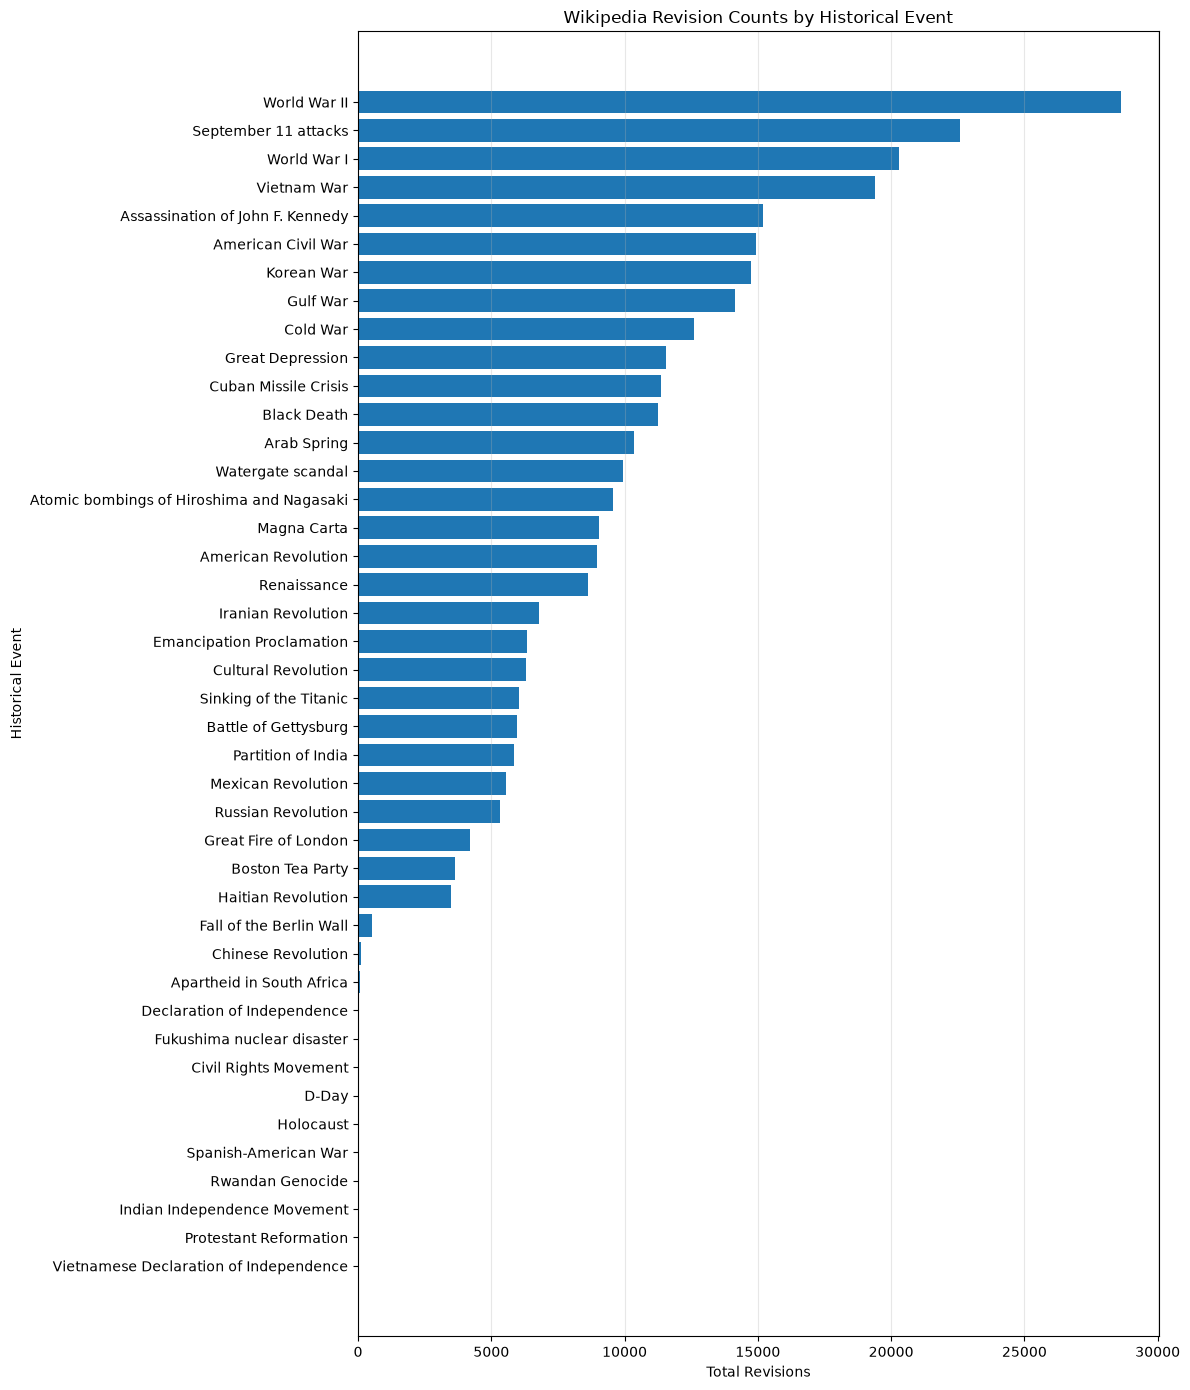

In [5]:
plot_df = successful.sort_values("revisions", ascending=True)

plt.figure(figsize=(12, 14))

plt.barh(
    plot_df["article"],
    plot_df["revisions"]
)

plt.xlabel("Total Revisions")
plt.ylabel("Historical Event")
plt.title("Wikipedia Revision Counts by Historical Event")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

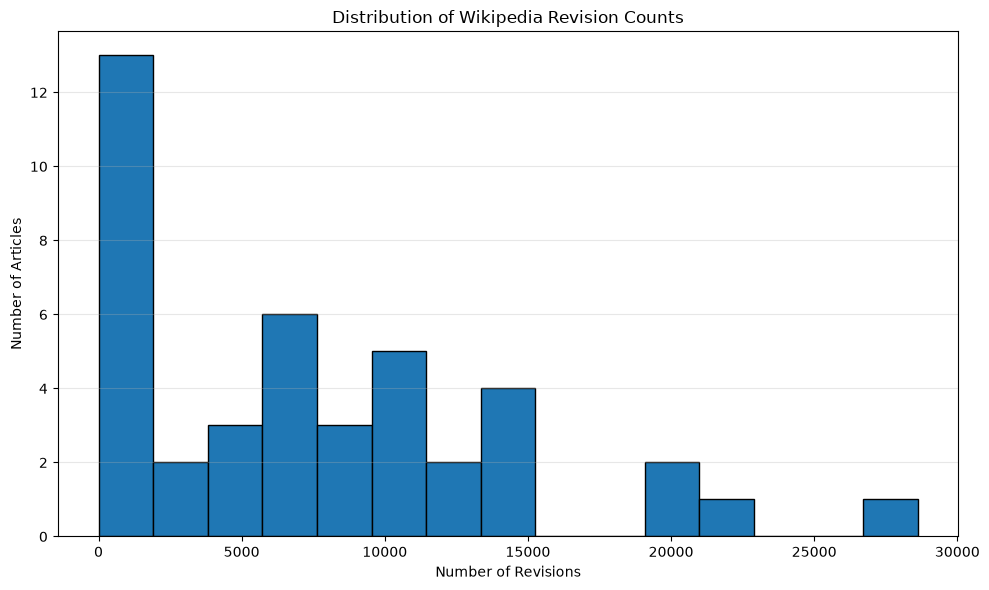

In [6]:
plt.figure(figsize=(10, 6))

plt.hist(
    successful["revisions"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Number of Revisions")
plt.ylabel("Number of Articles")
plt.title("Distribution of Wikipedia Revision Counts")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

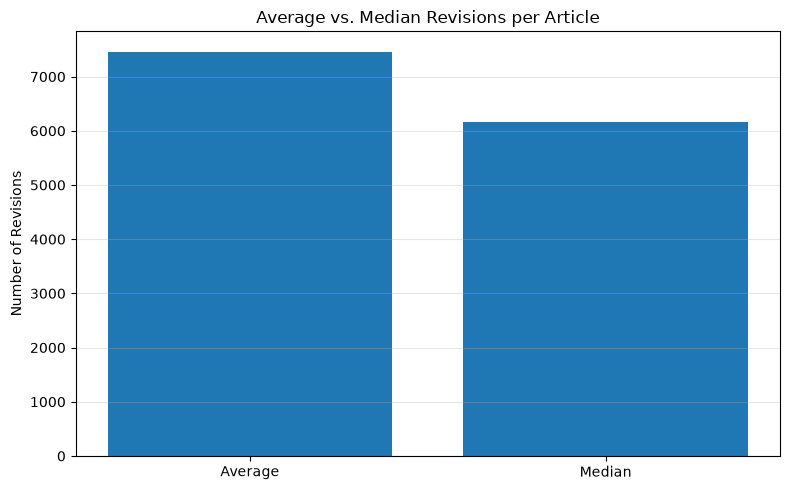

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Average", "Median"],
    [average_revisions, median_revisions]
)

plt.ylabel("Number of Revisions")
plt.title("Average vs. Median Revisions per Article")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
df.to_csv("historical_article_revision_counts.csv", index=False)

print("Saved historical_article_revision_counts.csv")

Saved historical_article_revision_counts.csv


In [9]:
# Minimum revision threshold
MIN_REVISIONS = 100

# Keep only successful articles with at least 100 revisions
cleaned_df = df[
    (df["status"] == "Success") &
    (df["revisions"].notna()) &
    (df["revisions"] >= MIN_REVISIONS)
].copy()

# Create a new list of article titles
CLEANED_ARTICLES = cleaned_df["article"].tolist()

# Display filtering results
removed_count = len(ARTICLES) - len(CLEANED_ARTICLES)

print("=" * 50)
print("ARTICLE CLEANING RESULTS")
print("=" * 50)

print(f"Original articles:       {len(ARTICLES)}")
print(f"Remaining articles:      {len(CLEANED_ARTICLES)}")
print(f"Removed articles:        {removed_count}")
print(f"Minimum revisions:       {MIN_REVISIONS:,}")

print("\nCleaned article list:")

for article in CLEANED_ARTICLES:
    print(f"- {article}")

# Save cleaned article titles
os.makedirs("../articleLists", exist_ok=True)

with open("../articleLists/cleaned_articles.txt", "w", encoding="utf-8") as file:
    file.write("ARTICLES = [\n")

    for article in CLEANED_ARTICLES:
        file.write(f'    "{article}",\n')

    file.write("]\n")

# Save complete cleaned revision-count dataset
cleaned_df.to_csv(
    "cleaned_article_revision_counts.csv",
    index=False
)

print("\nSaved:")
print("- cleaned_articles.txt")
print("- cleaned_article_revision_counts.csv")

ARTICLE CLEANING RESULTS
Original articles:       50
Remaining articles:      31
Removed articles:        19
Minimum revisions:       100

Cleaned article list:
- Vietnam War
- Watergate scandal
- World War II
- September 11 attacks
- American Revolution
- American Civil War
- World War I
- Cold War
- Fall of the Berlin Wall
- Russian Revolution
- Great Depression
- Atomic bombings of Hiroshima and Nagasaki
- Korean War
- Cuban Missile Crisis
- Assassination of John F. Kennedy
- Boston Tea Party
- Battle of Gettysburg
- Emancipation Proclamation
- Great Fire of London
- Black Death
- Renaissance
- Magna Carta
- Sinking of the Titanic
- Chinese Revolution
- Cultural Revolution
- Partition of India
- Iranian Revolution
- Gulf War
- Arab Spring
- Haitian Revolution
- Mexican Revolution

Saved:
- cleaned_articles.txt
- cleaned_article_revision_counts.csv


CLEANED HISTORICAL ARTICLES ANALYSIS
Articles analyzed:        31
Total revisions:          313,258
Average revisions/article: 10,105.10
Median revisions/article:  9,034
Minimum revisions:        108
Maximum revisions:        28,609

Most edited articles:
                         article  revisions
                    World War II    28609.0
            September 11 attacks    22585.0
                     World War I    20277.0
                     Vietnam War    19378.0
Assassination of John F. Kennedy    15182.0

Least edited articles:
                article  revisions
     Chinese Revolution      108.0
Fall of the Berlin Wall      542.0
     Haitian Revolution     3486.0
       Boston Tea Party     3643.0
   Great Fire of London     4193.0


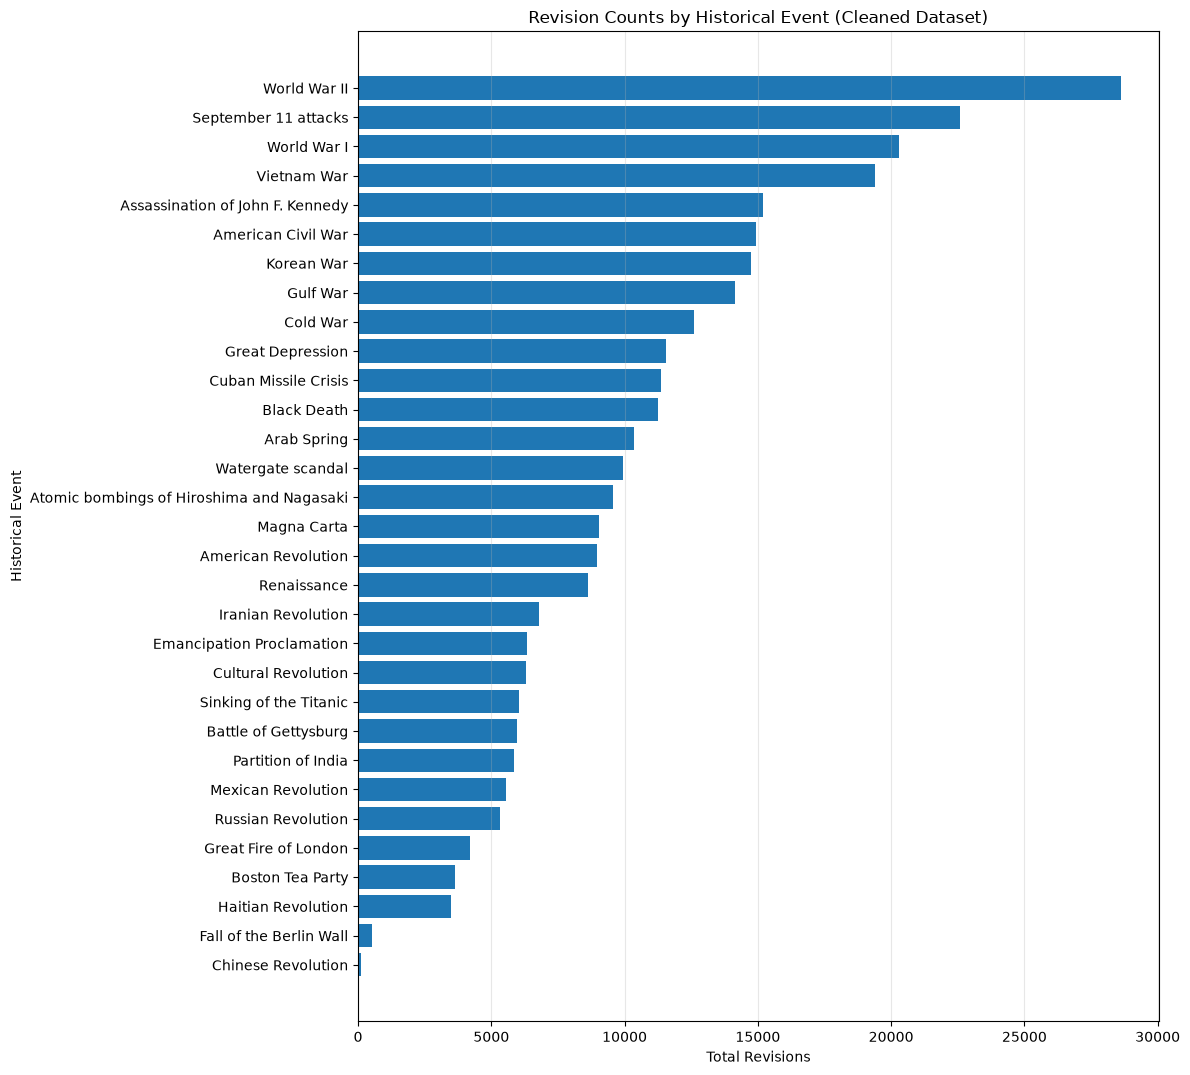

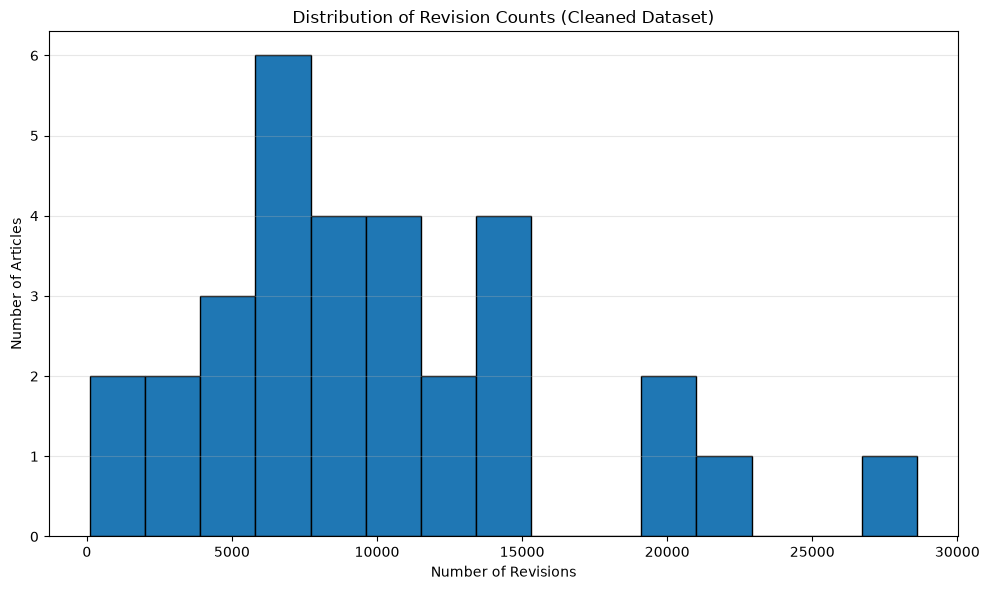

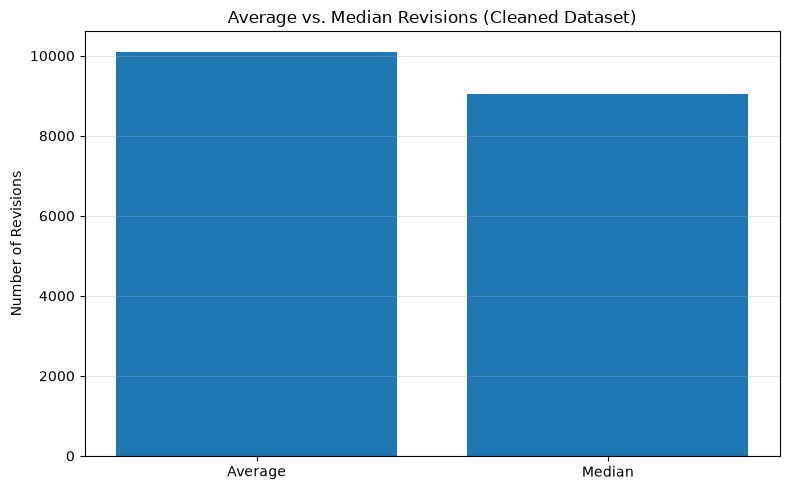


Saved cleaned_article_revision_analysis.csv


In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Filter original results to only cleaned articles
cleaned_analysis = df[
    df["article"].isin(CLEANED_ARTICLES)
].copy()

# Calculate statistics
total_revisions = cleaned_analysis["revisions"].sum()
average_revisions = cleaned_analysis["revisions"].mean()
median_revisions = cleaned_analysis["revisions"].median()

print("=" * 55)
print("CLEANED HISTORICAL ARTICLES ANALYSIS")
print("=" * 55)

print(f"Articles analyzed:        {len(cleaned_analysis)}")
print(f"Total revisions:          {total_revisions:,.0f}")
print(f"Average revisions/article: {average_revisions:,.2f}")
print(f"Median revisions/article:  {median_revisions:,.0f}")
print(f"Minimum revisions:        {cleaned_analysis['revisions'].min():,.0f}")
print(f"Maximum revisions:        {cleaned_analysis['revisions'].max():,.0f}")

print("\nMost edited articles:")
print(
    cleaned_analysis.nlargest(5, "revisions")[
        ["article", "revisions"]
    ].to_string(index=False)
)

print("\nLeast edited articles:")
print(
    cleaned_analysis.nsmallest(5, "revisions")[
        ["article", "revisions"]
    ].to_string(index=False)
)

# --------------------------------------------------
# Graph 1: Revisions per article
# --------------------------------------------------

plot_df = cleaned_analysis.sort_values(
    "revisions", ascending=True
)

plt.figure(figsize=(12, max(6, len(plot_df) * 0.35)))

plt.barh(plot_df["article"], plot_df["revisions"])

plt.xlabel("Total Revisions")
plt.ylabel("Historical Event")
plt.title("Revision Counts by Historical Event (Cleaned Dataset)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Graph 2: Distribution of revision counts
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    cleaned_analysis["revisions"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Number of Revisions")
plt.ylabel("Number of Articles")
plt.title("Distribution of Revision Counts (Cleaned Dataset)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Graph 3: Average vs. median
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Average", "Median"],
    [average_revisions, median_revisions]
)

plt.ylabel("Number of Revisions")
plt.title("Average vs. Median Revisions (Cleaned Dataset)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Save cleaned analysis
# --------------------------------------------------

cleaned_analysis.to_csv(
    "cleaned_article_revision_analysis.csv",
    index=False
)

print("\nSaved cleaned_article_revision_analysis.csv")